# HW2 Part 2 — Single-Stock Risk Report

This Papermill-ready notebook analyzes one stock over a requested date range. Returns and drawdown use adjusted close. The actual data coverage is reported because a stock may have a shorter history than the requested window.

In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = 'data/data.db'

In [2]:
# Parameters
ticker = "NVDA"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


In [3]:
from pathlib import Path
import json
import sqlite3

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import pandas as pd
import scrapbook as sb

# Use the personal homework folder as the notebook working directory.
database = Path(db_path).expanduser().resolve()
if not database.exists():
    raise FileNotFoundError(f"Database not found: {database}")

query = (
    "SELECT ts, ticker, adj_close "
    "FROM ohlc_hw_cleaned "
    "WHERE ticker = ? AND ts >= ? AND ts <= ? "
    "ORDER BY ts"
)
with sqlite3.connect(database) as connection:
    stock = pd.read_sql_query(query, connection, params=(ticker, start_date, end_date))

stock["ts"] = pd.to_datetime(stock["ts"], errors="coerce")
if stock.empty:
    raise ValueError(f"No data found for {ticker} from {start_date} to {end_date}.")
if stock["ts"].duplicated().any():
    raise ValueError(f"Duplicate dates found for {ticker}.")
if stock["adj_close"].isna().any() or stock["adj_close"].le(0).any():
    raise ValueError(f"Invalid adjusted prices found for {ticker}.")
if len(stock) < 21:
    raise ValueError(f"{ticker} has {len(stock)} prices; at least 21 prices are needed for 20 daily returns.")

print(f"{ticker} from {start_date} to {end_date}: {len(stock)} trading days")
print("Actual observation coverage:", stock["ts"].min().date(), "to", stock["ts"].max().date())
display(stock.head())
display(stock.tail())

NVDA from 2024-06-01 to 2024-11-30: 97 trading days
Actual observation coverage: 2024-06-03 to 2024-10-18


,ts,ticker,adj_close
0,2024-06-03,NVDA,114.98
1,2024-06-04,NVDA,116.42
2,2024-06-05,NVDA,122.42
3,2024-06-06,NVDA,120.98
4,2024-06-07,NVDA,120.87


,ts,ticker,adj_close
92,2024-10-14,NVDA,138.07
93,2024-10-15,NVDA,131.60
94,2024-10-16,NVDA,135.72
95,2024-10-17,NVDA,136.93
96,2024-10-18,NVDA,138.00


## Risk metric functions

Daily log return is `log(today's adjusted close / yesterday's adjusted close)`. Volatility and Sharpe are annualized using 252 trading days. Drawdown compares each price with the highest adjusted close seen so far.

In [4]:
def calculate_returns(prices):
    "Calculate daily log returns from a positive price series."
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns, window=20):
    "Calculate annualized rolling volatility using a full rolling window."
    return returns.rolling(window=window, min_periods=window).std(ddof=1) * np.sqrt(252)


def calculate_max_drawdown(prices):
    "Calculate each date's drawdown from the running adjusted-price peak."
    running_peak = prices.cummax()
    return prices / running_peak - 1


def calculate_sharpe_ratio(returns, risk_free_rate=0.02):
    "Calculate annualized Sharpe ratio using a 2% annual risk-free rate."
    returns = returns.dropna()
    daily_std = returns.std(ddof=1)
    if len(returns) < 2 or pd.isna(daily_std) or daily_std == 0:
        return np.nan
    return (returns.mean() * 252 - risk_free_rate) / (daily_std * np.sqrt(252))

In [5]:
stock = stock.sort_values("ts").reset_index(drop=True)
prices = stock["adj_close"].astype(float)
stock["daily_return"] = calculate_returns(prices)
stock["rolling_volatility"] = calculate_volatility(stock["daily_return"], window=20)
stock["drawdown"] = calculate_max_drawdown(prices)

returns = stock["daily_return"].dropna()
max_drawdown = stock["drawdown"].min()
annualized_return = np.exp(returns.sum() * 252 / len(returns)) - 1
annualized_volatility = returns.std(ddof=1) * np.sqrt(252)
up_days = returns[returns > 0]
down_days = returns[returns < 0]
summary = pd.DataFrame([
    ("Total Return", prices.iloc[-1] / prices.iloc[0] - 1),
    ("Annualized Return", annualized_return),
    ("Annualized Volatility", annualized_volatility),
    ("Sharpe Ratio", calculate_sharpe_ratio(returns)),
    ("Maximum Drawdown", max_drawdown),
    ("Best Day", returns.max()),
    ("Worst Day", returns.min()),
    ("Positive Days", (returns > 0).sum() / len(returns)),
    ("Average Up Day", up_days.mean() if not up_days.empty else np.nan),
    ("Average Down Day", down_days.mean() if not down_days.empty else np.nan),
], columns=["Metric", "Value"])

summary_display = summary.copy()
summary_display["Value"] = summary_display.apply(
    lambda row: "N/A" if pd.isna(row["Value"]) else (
        f"{row['Value']:.2f}" if row["Metric"] == "Sharpe Ratio" else f"{row['Value']:.2%}"
    ), axis=1,
)
display(summary_display)

# Named metrics let the batch runner collect outputs from successful notebooks only.
summary_payload = {
    "ticker": ticker,
    "avg_daily_return": float(returns.mean()),
    "avg_volatility": float(stock["rolling_volatility"].mean()),
    "max_drawdown": float(max_drawdown),
    "sharpe_ratio": float(calculate_sharpe_ratio(returns)) if pd.notna(calculate_sharpe_ratio(returns)) else None,
    "total_return": float(prices.iloc[-1] / prices.iloc[0] - 1),
    "actual_start": stock["ts"].min().strftime("%Y-%m-%d"),
    "actual_end": stock["ts"].max().strftime("%Y-%m-%d"),
}
sb.glue("summary_json", json.dumps(summary_payload), display=False)
print("Actual dates may be shorter than the shared requested window; compare tickers with that coverage in mind.")

,Metric,Value
0,Total Return,20.02%
1,Annualized Return,61.45%
2,Annualized Volatility,58.90%
3,Sharpe Ratio,0.78
4,Maximum Drawdown,-27.05%
5,Best Day,12.06%
6,Worst Day,-10.01%
7,Positive Days,54.17%
8,Average Up Day,2.82%
9,Average Down Day,-2.92%


Actual dates may be shorter than the shared requested window; compare tickers with that coverage in mind.


## Risk dashboard

The top-left line uses green for rolling volatility at or below its report-period mean, red for above-mean volatility, and gray during the 20-day warm-up. The other panels show daily log returns, rolling volatility, and per-date drawdown.

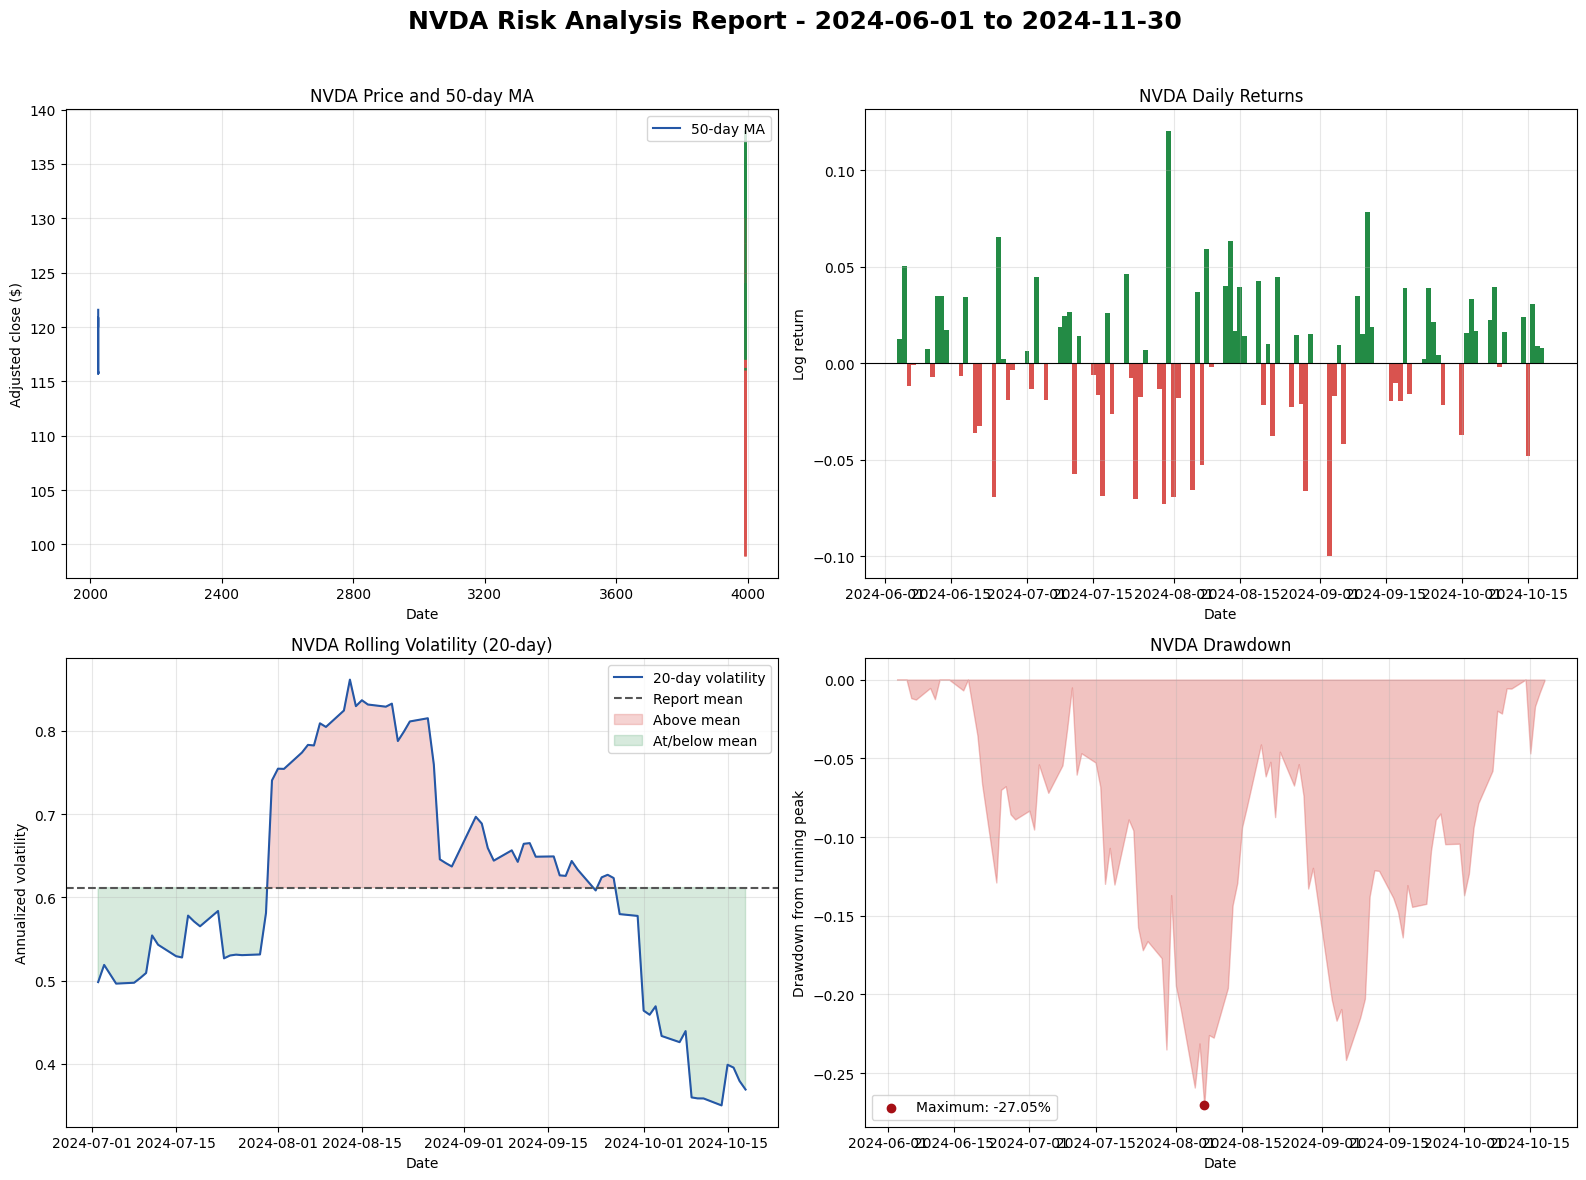

In [6]:
mean_volatility = stock["rolling_volatility"].mean()
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18, fontweight="bold")

# Price and moving average, with line segments colored by rolling volatility.
ax = axes[0, 0]
x = stock["ts"].map(pd.Timestamp.toordinal).to_numpy()
y = prices.to_numpy()
points = np.column_stack([x, y]).reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
volatility_by_segment = stock["rolling_volatility"].to_numpy()[1:]
segment_colors = [
    "#9aa0a6" if not np.isfinite(value) or pd.isna(mean_volatility)
    else ("#d9534f" if value > mean_volatility else "#238b45")
    for value in volatility_by_segment
]
ax.add_collection(LineCollection(segments, colors=segment_colors, linewidths=1.8))
ax.plot(stock["ts"], prices.rolling(50, min_periods=50).mean(), color="#2457a6", label="50-day MA", linewidth=1.5)
ax.autoscale()
ax.set_title(f"{ticker} Price and 50-day MA")
ax.set_ylabel("Adjusted close ($)")
ax.legend()

# Daily log returns.
ax = axes[0, 1]
colors = np.where(stock["daily_return"].fillna(0) >= 0, "#238b45", "#d9534f")
ax.bar(stock["ts"], stock["daily_return"], color=colors, width=1.0)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(f"{ticker} Daily Returns")
ax.set_ylabel("Log return")

# Rolling volatility, with high/low regions relative to its mean.
ax = axes[1, 0]
vol = stock["rolling_volatility"]
ax.plot(stock["ts"], vol, color="#2457a6", linewidth=1.5, label="20-day volatility")
if pd.notna(mean_volatility):
    ax.axhline(mean_volatility, color="#555555", linestyle="--", label="Report mean")
    ax.fill_between(stock["ts"], vol, mean_volatility, where=vol > mean_volatility,
                    color="#d9534f", alpha=0.25, interpolate=True, label="Above mean")
    ax.fill_between(stock["ts"], vol, mean_volatility, where=vol <= mean_volatility,
                    color="#238b45", alpha=0.18, interpolate=True, label="At/below mean")
ax.set_title(f"{ticker} Rolling Volatility (20-day)")
ax.set_ylabel("Annualized volatility")
ax.legend()

# Per-date drawdown and the report-period maximum drawdown.
ax = axes[1, 1]
ax.fill_between(stock["ts"], stock["drawdown"], 0, color="#d9534f", alpha=0.35)
max_index = stock["drawdown"].idxmin()
ax.scatter(stock.loc[max_index, "ts"], stock.loc[max_index, "drawdown"], color="#a50f15", zorder=3,
           label=f"Maximum: {stock.loc[max_index, 'drawdown']:.2%}")
ax.set_title(f"{ticker} Drawdown")
ax.set_ylabel("Drawdown from running peak")
ax.legend()

for ax in axes.flat:
    ax.grid(True, alpha=0.3)
    ax.set_xlabel("Date")
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()